In [1]:
  import sys; sys.executable

'C:\\Users\\ryono\\miniconda3\\python.exe'

In [2]:
from src.mnist import load_mnist, plot_example

splits = load_mnist()
X_train, y_train = splits["train"]
X_val, y_val = splits["val"]
X_test, y_test = splits["test"]

print(f"train: {X_train.shape}, {y_train.shape}")
print(f"val:   {X_val.shape}, {y_val.shape}")
print(f"test:  {X_test.shape}, {y_test.shape}")

train: (50000, 28, 28), (50000,)
val:   (10000, 28, 28), (10000,)
test:  (10000, 28, 28), (10000,)


This loads the MNIST dataset and splits into train/val/test datasets

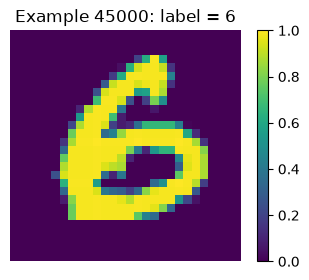

In [3]:
plot_example(X_train, y_train, i=45000);

This plots the ith example from the training dataset

In [4]:
from src.network import NeuralNetwork

net = NeuralNetwork([784, 64,64 , 10], activation="sigmoid")
print(net)
for l, (W, b) in enumerate(zip(net.weights, net.biases), start=1):
    print(f"layer {l}: W {W.shape}, b {b.shape}")

NeuralNetwork([784, 64, 64, 10], activation='sigmoid')
layer 1: W (64, 784), b (64, 1)
layer 2: W (64, 64), b (64, 1)
layer 3: W (10, 64), b (10, 1)


Here we initialize the network with 784 input neurons (for the 28x28 pixels and 10 output neurons for the number of classes. You can initialize an arbitrary number of hidden layers and hidden neurons. Also, you can choose the activation function, where the class defines sigmoid and tanh activation functions.

In [5]:
print("untrained val accuracy:", (net.predict(X_val) == y_val).mean())

untrained val accuracy: 0.0994


This runs the forward pass on the current net and gives the validation accuracy based on the validation dataset. Here its untrained so accuracy is expected be about ~10%.

In [6]:
from src.backprop import backprop

net_trained, history = backprop(net, X_train, y_train, epochs=50, loss="ce", lr=0.1, batch_size=32,
                       X_test=X_test, y_test=y_test)
print("trained val accuracy:", (net_trained.predict(X_val) == y_val).mean())

epoch 1/50: loss 1.8858, train acc 0.8560, test acc 0.8561
epoch 2/50: loss 0.7541, train acc 0.9105, test acc 0.9107
epoch 3/50: loss 0.5605, train acc 0.9259, test acc 0.9243
epoch 4/50: loss 0.4679, train acc 0.9381, test acc 0.9373
epoch 5/50: loss 0.4029, train acc 0.9453, test acc 0.9437
epoch 6/50: loss 0.3545, train acc 0.9520, test acc 0.9474
epoch 7/50: loss 0.3176, train acc 0.9582, test acc 0.9522
epoch 8/50: loss 0.2885, train acc 0.9612, test acc 0.9550
epoch 9/50: loss 0.2647, train acc 0.9651, test acc 0.9585
epoch 10/50: loss 0.2440, train acc 0.9689, test acc 0.9611
epoch 11/50: loss 0.2268, train acc 0.9687, test acc 0.9608
epoch 12/50: loss 0.2125, train acc 0.9732, test acc 0.9644
epoch 13/50: loss 0.1999, train acc 0.9749, test acc 0.9650
epoch 14/50: loss 0.1881, train acc 0.9767, test acc 0.9675
epoch 15/50: loss 0.1781, train acc 0.9783, test acc 0.9675
epoch 16/50: loss 0.1686, train acc 0.9794, test acc 0.9678
epoch 17/50: loss 0.1603, train acc 0.9804, test 

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

epochs = np.arange(1, len(history["train_acc"]) + 1)
fig, ax = plt.subplots(figsize=(7, 4))
for key, label, color in [("train_acc", "Train", "#2a6fdb"), ("test_acc", "Test", "#e8710a")]:
    ax.plot(epochs, history[key], color=color, linewidth=2, label=label)
    # Label the end of each line with its final accuracy.
    ax.annotate(f"{label} {history[key][-1]:.3f}", (epochs[-1], history[key][-1]),
                xytext=(5, 0), textcoords="offset points", va="center", color="0.25")
ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy")
ax.set_title("Training and test accuracy vs. epoch")
ax.legend(frameon=False)
ax.grid(True, color="0.9")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

Each layer is programmed onto a crossbar of memristors with conductances in **0.1–150 µS**. Signed weights use a differential pair (w ∝ G⁺ − G⁻), and the bias is one extra row driven at a constant voltage, so every parameter is a conductance. Programming adds Gaussian noise with **σ = 0.1 µS** to every device (about 8-bit precision), then clips to the device range. Inference runs through the crossbars as VMMs: input activations become row voltages and the column currents give the pre-activations.

In [8]:
from src.crossbar import CrossbarNetwork, G_MIN, G_MAX, SIGMA

ideal_acc = (net_trained.predict(X_test) == y_test).mean()
chip = CrossbarNetwork(net_trained, sigma=SIGMA)
chip_acc = (chip.predict(X_test) == y_test).mean()

print(f"conductance range {G_MIN}-{G_MAX} uS, programming noise sigma = {SIGMA} uS")
print(f"ideal (software) test accuracy: {ideal_acc:.4f}")
print(f"crossbar test accuracy:         {chip_acc:.4f}")

conductance range 0.1-150.0 uS, programming noise sigma = 0.1 uS
ideal (software) test accuracy: 0.9752
crossbar test accuracy:         0.9753
